# Y-Net Capsule Image Classification — DenseNet + VQC

**Adapted from the earlier LIDC notebook (itself adapted from the DR notebook) for the supplied `Y-Net_Capsule` ZIP.** The ZIP is organised as `Train/` and `Val/`, each containing `Benign_new`, `Malignant` and `Normal` folders. This notebook treats them as a three-class **image-classification** dataset (`benign`, `malignant`, `normal`). The ZIP contains no segmentation masks, so this notebook does **not** train a Y-Net segmentation model.

### Pipeline
1. Extract and audit the dataset (both `Train/` and `Val/`).
2. Pool Train + Val, select one canonical image per source ID, and exclude source IDs whose images appear under conflicting labels.
3. Re-split the source images 70/15/15 into train/validation/test **by source ID** (the ZIP has no test set, and some source IDs have variants in both `Train/` and `Val/`); augment only training images on the fly.
4. Fine-tune an ImageNet-pretrained DenseNet-121 with early stopping.
5. Extract DenseNet features and train a **new VQC for this dataset** using train-fitted preprocessing.
6. Tune a DenseNet/VQC probability-fusion weight using validation data only, then evaluate both models and the combined prediction on the held-out test split.
7. Export classification metrics, confusion matrices, uncertainty flags, and Grad-CAM++ examples.

**Important:** no checkpoints, CSVs or VQC features from the DR or LIDC notebooks are loaded. Results must be measured afresh and should not be presented as clinical performance.

## 1. Environment and Google Drive

Run from top to bottom in Google Colab. Put `Y-Net_Capsule.zip` in the root of My Drive, or upload it when prompted. The extracted dataset is kept in the Colab runtime; results and checkpoints are saved to Google Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

%pip -q install timm pennylane scikit-learn joblib matplotlib pandas pillow torchvision

import os, re, json, time, math, random, warnings, zipfile
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import joblib

import torch
import torch.nn as nn
import timm
import pennylane as qml
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = torch.cuda.is_available()

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NUM_WORKERS = 2
PIN_MEMORY = DEVICE.type == 'cuda'
print('PyTorch:', torch.__version__)
print('timm:', timm.__version__)
print('PennyLane:', qml.__version__)
print('Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))

Mounted at /content/drive
PyTorch: 2.11.0+cu130
timm: 1.0.30
PennyLane: 0.45.1
Device: cuda
GPU: NVIDIA A100-SXM4-40GB


## 2. Dataset paths, extraction, and class definitions

If the ZIP is stored in a different Drive folder, update `DATA_ZIP` below (any file matching `Y-Net_Capsule*.zip` in the root of My Drive is also found automatically). The expected extracted structure is `Y-Net_Capsule/Train/{Benign_new,Malignant,Normal}` and `Y-Net_Capsule/Val/{Benign_new,Malignant,Normal}`. The folder `Benign_new` is mapped to the class `benign`.

In [ ]:
# --- Change this path if the ZIP is stored elsewhere in Google Drive ---
DATA_ZIP = Path('/content/drive/MyDrive/Y-Net_Capsule.zip')
EXTRACT_DIR = Path('/content/ynet_capsule_extracted')
DATA_ROOT = EXTRACT_DIR / 'Y-Net_Capsule'

RESULTS_DIR = Path('/content/drive/MyDrive/YNet_Capsule_Results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['benign', 'malignant', 'normal']
CLASS_TO_ID = {name: idx for idx, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

# Folder names inside Train/ and Val/ -> class names (the benign folder is called 'Benign_new').
FOLDER_TO_CLASS = {'benign_new': 'benign', 'benign': 'benign', 'malignant': 'malignant', 'normal': 'normal'}
SOURCE_SPLITS = ['Train', 'Val']   # pooled and re-split below; the ZIP has no test set

def has_structure(root):
    return root.is_dir() and all((root / s).is_dir() for s in SOURCE_SPLITS)

if not DATA_ZIP.exists():
    alternatives = sorted(Path('/content/drive/MyDrive').glob('Y-Net_Capsule*.zip')) + sorted(Path('/content').glob('Y-Net_Capsule*.zip'))
    if alternatives:
        DATA_ZIP = alternatives[0]
    else:
        from google.colab import files
        print('ZIP not found in the expected Drive locations. Upload Y-Net_Capsule.zip now.')
        uploaded = files.upload()
        zips = [Path('/content') / name for name in uploaded if name.lower().endswith('.zip')]
        if not zips:
            raise FileNotFoundError('No ZIP was uploaded. Upload the Y-Net_Capsule dataset ZIP and rerun this cell.')
        DATA_ZIP = zips[0]

if not has_structure(DATA_ROOT):
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    print(f'Extracting {DATA_ZIP} to {EXTRACT_DIR} ...')
    with zipfile.ZipFile(DATA_ZIP) as zf:
        zf.extractall(EXTRACT_DIR)

if not has_structure(DATA_ROOT):
    # Locate a nested folder containing both Train/ and Val/.
    candidates = [p for p in EXTRACT_DIR.rglob('*') if has_structure(p)]
    if candidates:
        DATA_ROOT = candidates[0]
    else:
        raise FileNotFoundError(
            f'Could not find Train/ and Val/ folders under {EXTRACT_DIR}. '
            'Inspect the ZIP structure and update DATA_ROOT.'
        )

print('Dataset ZIP:', DATA_ZIP)
print('Dataset root:', DATA_ROOT)
print('Results folder:', RESULTS_DIR)

Extracting /content/drive/MyDrive/Y-Net_Capsule.zip to /content/ynet_capsule_extracted ...
Dataset ZIP: /content/drive/MyDrive/Y-Net_Capsule.zip
Dataset root: /content/ynet_capsule_extracted/Y-Net_Capsule
Results folder: /content/drive/MyDrive/YNet_Capsule_Results


## 3. Audit variants and create leakage-aware splits

The supplied filenames include derived variants such as `cropped`, `hflip`, `vflip`, `rotateflip` and `rotatflip`. `Normal` images are single files (`Normal case (N).jpg`) with no variants; `Malignant` images are named `Malignant case (N)Cropped...`; `Benign_new` images use numeric or `img-...` IDs. To avoid counting transformed copies as independent samples, this notebook selects one canonical image per source ID (the filename prefix before `Resized`) and uses on-the-fly augmentation only for training.

The ZIP's own `Train/`/`Val/` split is **not** used for evaluation: it has no test set, and an audit of the ZIP found source IDs whose variants are spread across `Train/` and `Val/` (e.g. `27119`, `Malignant case (177)Cropped`), which would leak. Instead, Train and Val are pooled, grouped by source ID, and re-split 70/15/15 stratified by class. If the same source ID appears under more than one class, that ID is excluded because its label is ambiguous.

The audit also reports image sizes per class: in this ZIP the `Normal` images are 512×512 while `Benign`/`Malignant` are mostly 256×256, so a model could learn image size instead of content. Section 4 mitigates this by putting every image through the same resize chain.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}
records = []

for split_name in SOURCE_SPLITS:
    split_dir = DATA_ROOT / split_name
    for folder in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        class_name = FOLDER_TO_CLASS.get(folder.name.lower())
        if class_name is None:
            print('Skipping unrecognised folder:', folder)
            continue
        for path in sorted(folder.rglob('*')):
            if path.is_file() and path.suffix.lower() in IMAGE_EXTS:
                stem = path.stem
                # Variants are named <source_id>Resized<suffix>; Normal images have no 'Resized' and are single files.
                if 'Resized' in stem:
                    source_id, variant_suffix = stem.split('Resized', 1)
                else:
                    source_id, variant_suffix = stem, ''
                records.append({
                    'class_name': class_name,
                    'label': CLASS_TO_ID[class_name],
                    'source_id': source_id.strip(),
                    'variant_suffix': variant_suffix.lower(),
                    'original_split': split_name,
                    'path': str(path),
                    'filename': path.name,
                })

all_df = pd.DataFrame(records)
if all_df.empty:
    raise RuntimeError(f'No image files found below {DATA_ROOT}')

print('All image files by original split and class (includes derivatives):')
display(pd.crosstab(all_df['original_split'], all_df['class_name']).reindex(columns=CLASS_NAMES, fill_value=0))
print('Variant suffix counts:', dict(Counter(all_df['variant_suffix'])))

# Identify IDs that occur under more than one label and exclude those IDs from every split.
labels_per_source = all_df.groupby('source_id')['class_name'].agg(lambda x: sorted(set(x)))
conflicting_ids = set(labels_per_source[labels_per_source.map(len) > 1].index)
conflicts_df = all_df[all_df['source_id'].isin(conflicting_ids)].sort_values(['source_id', 'class_name', 'filename'])
conflicts_df.to_csv(RESULTS_DIR / 'excluded_conflicting_source_ids.csv', index=False)

# Source IDs whose variants are spread across the ZIP's own Train/ and Val/ folders (would leak if that split were used).
splits_per_source = all_df.groupby('source_id')['original_split'].agg(lambda x: sorted(set(x)))
cross_split_ids = sorted(splits_per_source[splits_per_source.map(len) > 1].index)
all_df[all_df['source_id'].isin(cross_split_ids)].sort_values(['source_id', 'original_split', 'filename']).to_csv(
    RESULTS_DIR / 'source_ids_spanning_original_train_val.csv', index=False)

clean_df = all_df[~all_df['source_id'].isin(conflicting_ids)].copy()

# Canonical file selection: the plain '...Resized' original (suffix '') first, then the 'Resizedn' copy;
# fall back to the shortest-suffix file only if neither exists (logged below).
CANONICAL_PRIORITY = {'': 0, 'resizedn': 1, 'n': 1}
canonical_rows, fallback_ids = [], []
for (class_name, source_id), group in clean_df.groupby(['class_name', 'source_id'], sort=True):
    group = group.assign(
        _priority=group['variant_suffix'].map(CANONICAL_PRIORITY).fillna(99),
        _suffix_len=group['variant_suffix'].str.len(),
    ).sort_values(['_priority', '_suffix_len', 'filename'])
    chosen = group.iloc[0]
    if chosen['_priority'] == 99:
        fallback_ids.append(source_id)
    canonical_rows.append(chosen.drop(labels=['_priority', '_suffix_len']).to_dict())

manifest = pd.DataFrame(canonical_rows).drop_duplicates(subset=['source_id']).reset_index(drop=True)
if manifest['source_id'].duplicated().any():
    raise AssertionError('Source IDs are not unique after canonical selection; inspect the filename grouping logic.')

# Image-size audit per class (a size difference between classes is a possible shortcut for the model).
sizes = []
for p in manifest['path']:
    with Image.open(p) as im:
        sizes.append(im.size)
manifest['width'] = [s[0] for s in sizes]
manifest['height'] = [s[1] for s in sizes]
print('\nCanonical image sizes per class (width x height -> count):')
for class_name in CLASS_NAMES:
    sub_df = manifest[manifest['class_name'] == class_name]
    print(f'  {class_name:10s}', dict(Counter(zip(sub_df["width"], sub_df["height"])).most_common(4)))
dominant = {c: Counter(zip(g['width'], g['height'])).most_common(1)[0][0] for c, g in manifest.groupby('class_name')}
if len(set(dominant.values())) > 1:
    print('WARNING: the dominant image size differs between classes:', dominant,
          '-> all images are pre-resized to a common size in Section 4, but interpret results with care.')

# Deterministic approximately 70/15/15 split, stratified by class at the source-image level.
train_df, temp_df = train_test_split(
    manifest, test_size=0.30, random_state=SEED, stratify=manifest['label']
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df['label']
)
train_df = train_df.copy().assign(split='train').sort_values('source_id').reset_index(drop=True)
valid_df = valid_df.copy().assign(split='valid').sort_values('source_id').reset_index(drop=True)
test_df = test_df.copy().assign(split='test').sort_values('source_id').reset_index(drop=True)

split_manifest = pd.concat([train_df, valid_df, test_df], ignore_index=True)
# A final safety check: no source ID should occur across splits.
assert split_manifest.groupby('source_id')['split'].nunique().max() == 1
split_manifest.to_csv(RESULTS_DIR / 'dataset_split_manifest.csv', index=False)

print(f'\nRaw image files: {len(all_df)}')
print(f'Source IDs spanning the ZIP\'s Train and Val folders (now kept together): {len(cross_split_ids)} -> {cross_split_ids}')
print(f'Conflicting source IDs excluded: {len(conflicting_ids)} -> {sorted(conflicting_ids)}')
print(f'Source IDs with no plain original (fallback variant used): {len(fallback_ids)}')
print(f'Canonical source images retained: {len(manifest)}')
print(f'Train / validation / test: {len(train_df)} / {len(valid_df)} / {len(test_df)}')
display(pd.crosstab(split_manifest['split'], split_manifest['class_name']).reindex(index=['train','valid','test'], columns=CLASS_NAMES, fill_value=0))
print('Saved manifest:', RESULTS_DIR / 'dataset_split_manifest.csv')
print('Saved conflicts audit:', RESULTS_DIR / 'excluded_conflicting_source_ids.csv')
print('Saved cross-split audit:', RESULTS_DIR / 'source_ids_spanning_original_train_val.csv')

All image files by original split and class (includes derivatives):


class_name,benign,malignant,normal
original_split,,,
Train,473,480,332
Val,119,120,84


Variant suffix counts: {'': 615, 'cropped': 97, 'hflip': 199, 'rotateflip': 199, 'rotatflip': 199, 'vflip': 199, 'resizedn': 100}

Canonical image sizes per class (width x height -> count):
  benign     {(256, 256): 99}
  malignant  {(256, 256): 100}
  normal     {(512, 512): 415, (506, 331): 1}

Raw image files: 1608
Source IDs spanning the ZIP's Train and Val folders (now kept together): 4 -> ['27119', 'Malignant case (177)Cropped', 'Malignant case (178)Cropped', 'Malignant case (179)Cropped']
Conflicting source IDs excluded: 0 -> []
Source IDs with no plain original (fallback variant used): 0
Canonical source images retained: 615
Train / validation / test: 430 / 92 / 93


class_name,benign,malignant,normal
split,,,
train,69,70,291
valid,15,15,62
test,15,15,63


Saved manifest: /content/drive/MyDrive/YNet_Capsule_Results/dataset_split_manifest.csv
Saved conflicts audit: /content/drive/MyDrive/YNet_Capsule_Results/excluded_conflicting_source_ids.csv
Saved cross-split audit: /content/drive/MyDrive/YNet_Capsule_Results/source_ids_spanning_original_train_val.csv


## 4. Image datasets and DataLoaders

All canonical images are first resized to a common 256×256 (so `Normal` 512×512 images and the 256×256 `Benign`/`Malignant` images go through the same pipeline), then to the network input size and normalized using ImageNet statistics. Random augmentation is applied only while training DenseNet; validation and test images are deterministic. For this small dataset, transfer learning is strongly preferred over training a deep network from scratch.

In [ ]:
IMAGE_SIZE = 224
PRE_RESIZE = 256   # common size first: Normal images are 512x512, Benign/Malignant mostly 256x256
BATCH_SIZE = 16
TRAIN_BATCH_SIZE = 16

train_transform = transforms.Compose([
    transforms.Resize((PRE_RESIZE, PRE_RESIZE)),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
eval_transform = transforms.Compose([
    transforms.Resize((PRE_RESIZE, PRE_RESIZE)),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class CapsuleImageDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True).copy()
        self.transform = transform
        self.paths = self.df['path'].tolist()
        self.labels = self.df['label'].astype(int).to_numpy()
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        path = self.paths[idx]
        try:
            with Image.open(path) as im:
                image = im.convert('RGB')
        except Exception as e:
            raise RuntimeError(f'Could not read image: {path}') from e
        return self.transform(image), int(self.labels[idx]), idx

train_ds = CapsuleImageDataset(train_df, train_transform)
train_eval_ds = CapsuleImageDataset(train_df, eval_transform)  # no augmentation for VQC feature generation
valid_ds = CapsuleImageDataset(valid_df, eval_transform)
test_ds = CapsuleImageDataset(test_df, eval_transform)

train_loader = DataLoader(train_ds, batch_size=TRAIN_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)

y_train = train_df['label'].astype(int).to_numpy()
y_valid = valid_df['label'].astype(int).to_numpy()
y_test = test_df['label'].astype(int).to_numpy()
print('Class mapping:', CLASS_TO_ID)
print('Unique canonical images:', len(train_ds), len(valid_ds), len(test_ds))

Class mapping: {'benign': 0, 'malignant': 1, 'normal': 2}
Unique canonical images: 430 92 93


## 5. Train DenseNet-121 for three-class classification

This starts from ImageNet-pretrained DenseNet-121, replaces the classifier with three outputs, and fine-tunes on the new dataset. Early stopping selects the best validation Macro-F1 checkpoint. No DR checkpoints are loaded.

In [ ]:
EPOCHS = 100
PATIENCE = 98
MIN_DELTA = 0.001
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4
USE_IMAGENET_PRETRAINED = True

DENSENET_CKPT = RESULTS_DIR / 'densenet121_capsule3class_best.pt'
DENSENET_HISTORY = RESULTS_DIR / 'densenet121_training_history.csv'

try:
    model = timm.create_model(
        'densenet121', pretrained=USE_IMAGENET_PRETRAINED,
        num_classes=NUM_CLASSES, drop_rate=0.2
    )
except Exception as e:
    raise RuntimeError(
        'Could not create DenseNet-121 with pretrained ImageNet weights. '
        'Check Colab internet access/model-weight download, or set USE_IMAGENET_PRETRAINED=False '
        '(training from scratch on this small dataset is not recommended).'
    ) from e
model = model.to(DEVICE)

class_counts = np.bincount(y_train, minlength=NUM_CLASSES).astype(np.float32)
class_weights = 1.0 / np.sqrt(np.maximum(class_counts, 1.0))
class_weights = class_weights / class_weights.mean()
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32, device=DEVICE))
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
use_amp = DEVICE.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

best_val_macro_f1 = -1.0
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    started = time.time()
    model.train()
    total_loss, seen = 0.0, 0
    for xb, yb, _ in train_loader:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
            logits = model(xb)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        total_loss += float(loss.detach()) * len(yb)
        seen += len(yb)

    model.eval()
    val_true, val_pred = [], []
    with torch.inference_mode():
        for xb, yb, _ in valid_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                logits = model(xb)
            val_pred.extend(logits.argmax(1).cpu().numpy().tolist())
            val_true.extend(yb.numpy().tolist())

    val_macro = f1_score(val_true, val_pred, average='macro', zero_division=0)
    val_acc = accuracy_score(val_true, val_pred)
    row = {
        'epoch': epoch,
        'train_loss': total_loss / max(seen, 1),
        'validation_accuracy': val_acc,
        'validation_macro_f1': val_macro,
        'seconds': time.time() - started,
    }
    history.append(row)
    print(f"Epoch {epoch:03d}/{EPOCHS} | loss={row['train_loss']:.4f} | val_acc={val_acc:.4f} | val_macro_F1={val_macro:.4f} | {row['seconds']:.1f}s")

    if val_macro > best_val_macro_f1 + MIN_DELTA:
        best_val_macro_f1 = val_macro
        epochs_without_improvement = 0
        torch.save({
            'model_state_dict': model.state_dict(),
            'class_names': CLASS_NAMES,
            'num_classes': NUM_CLASSES,
            'image_size': IMAGE_SIZE,
            'best_validation_macro_f1': best_val_macro_f1,
            'epoch': epoch,
            'seed': SEED,
        }, DENSENET_CKPT)
        print('  Saved best DenseNet checkpoint:', DENSENET_CKPT)
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; no validation Macro-F1 improvement for {PATIENCE} epochs.')
        break

pd.DataFrame(history).to_csv(DENSENET_HISTORY, index=False)
if not DENSENET_CKPT.exists():
    raise RuntimeError('DenseNet checkpoint was not saved; inspect training logs.')
print('Best validation Macro-F1:', best_val_macro_f1)
print('Best checkpoint:', DENSENET_CKPT)
print('Training history:', DENSENET_HISTORY)

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 001/100 | loss=0.7068 | val_acc=0.9783 | val_macro_F1=0.9554 | 39.4s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/densenet121_capsule3class_best.pt
Epoch 002/100 | loss=0.1859 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
  Saved best DenseNet checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/densenet121_capsule3class_best.pt
Epoch 003/100 | loss=0.0995 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
Epoch 004/100 | loss=0.0730 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
Epoch 005/100 | loss=0.0726 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.1s
Epoch 006/100 | loss=0.0361 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
Epoch 007/100 | loss=0.0329 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
Epoch 008/100 | loss=0.0186 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.0s
Epoch 009/100 | loss=0.0175 | val_acc=1.0000 | val_macro_F1=1.0000 | 3.2s
Epoch 010/100 | loss=0.0143 | val_acc=1.0000 | val_macro_F1=1.0000 | 2.9s
Epoch 011/100 | loss=0.0124 | val_a

## 6. Load the best DenseNet checkpoint and evaluate its outputs

The saved checkpoint is reloaded before features are extracted for VQC. This ensures VQC uses features from the finalized DenseNet checkpoint, not from an intermediate epoch.

In [ ]:
checkpoint = torch.load(DENSENET_CKPT, map_location='cpu', weights_only=False)
model = timm.create_model('densenet121', pretrained=False, num_classes=NUM_CLASSES, drop_rate=0.2)
model.load_state_dict(checkpoint['model_state_dict'], strict=True)
model = model.to(DEVICE).eval()
print('Loaded DenseNet checkpoint from epoch:', checkpoint.get('epoch'))
print('Checkpoint validation Macro-F1:', checkpoint.get('best_validation_macro_f1'))

@torch.inference_mode()
def get_probabilities(net, loader):
    all_probs, all_labels = [], []
    net.eval()
    for xb, yb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == 'cuda')):
            logits = net(xb)
        all_probs.append(torch.softmax(logits, dim=1).cpu().numpy())
        all_labels.extend(yb.numpy().tolist())
    return np.concatenate(all_probs, axis=0), np.asarray(all_labels, dtype=np.int64)

val_dense_probs, y_valid_check = get_probabilities(model, valid_loader)
test_dense_probs, y_test_check = get_probabilities(model, test_loader)
assert np.array_equal(y_valid_check, y_valid)
assert np.array_equal(y_test_check, y_test)
print('DenseNet validation/test probability arrays:', val_dense_probs.shape, test_dense_probs.shape)

Loaded DenseNet checkpoint from epoch: 2
Checkpoint validation Macro-F1: 1.0
DenseNet validation/test probability arrays: (92, 3) (93, 3)


## 7. Extract DenseNet embeddings and fit VQC preprocessing

The VQC is newly trained for these three classes. We use the finalized DenseNet's pooled feature vector, then fit `StandardScaler`, 4-component PCA, and an angle scaler on **training embeddings only**. Validation and test data are transformed with those same fitted objects to avoid preprocessing leakage.

In [ ]:
@torch.inference_mode()
def extract_densenet_embeddings(net, loader):
    net.eval()
    feature_batches, label_batches = [], []
    for xb, yb, _ in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        fmap = net.forward_features(xb)
        # Prefer timm's pre-logit embedding API; keep a compatibility fallback for older timm versions.
        try:
            embeddings = net.forward_head(fmap, pre_logits=True)
        except TypeError:
            pooled = net.global_pool(fmap)
            embeddings = pooled.flatten(1) if pooled.ndim > 2 else pooled
        feature_batches.append(embeddings.detach().cpu().numpy().astype(np.float32))
        label_batches.extend(yb.numpy().tolist())
    return np.concatenate(feature_batches, axis=0), np.asarray(label_batches, dtype=np.int64)

X_train_emb, y_train_feature = extract_densenet_embeddings(model, train_eval_loader)
X_valid_emb, y_valid_feature = extract_densenet_embeddings(model, valid_loader)
X_test_emb, y_test_feature = extract_densenet_embeddings(model, test_loader)
assert np.array_equal(y_train_feature, y_train)
assert np.array_equal(y_valid_feature, y_valid)
assert np.array_equal(y_test_feature, y_test)

N_QUBITS = 4
if X_train_emb.shape[1] < N_QUBITS:
    raise ValueError(f'Need at least {N_QUBITS} DenseNet feature dimensions; got {X_train_emb.shape[1]}')
feature_scaler = StandardScaler()
X_train_std = feature_scaler.fit_transform(X_train_emb)
X_valid_std = feature_scaler.transform(X_valid_emb)
X_test_std = feature_scaler.transform(X_test_emb)

pca = PCA(n_components=N_QUBITS, random_state=SEED)
X_train_pca = pca.fit_transform(X_train_std)
X_valid_pca = pca.transform(X_valid_std)
X_test_pca = pca.transform(X_test_std)

angle_scaler = MinMaxScaler(feature_range=(0.0, np.pi))
X_train_vqc = np.clip(angle_scaler.fit_transform(X_train_pca), 0.0, np.pi).astype(np.float32)
X_valid_vqc = np.clip(angle_scaler.transform(X_valid_pca), 0.0, np.pi).astype(np.float32)
X_test_vqc = np.clip(angle_scaler.transform(X_test_pca), 0.0, np.pi).astype(np.float32)

PREPROCESSOR_PATH = RESULTS_DIR / 'vqc_feature_preprocessing.joblib'
joblib.dump({'feature_scaler': feature_scaler, 'pca': pca, 'angle_scaler': angle_scaler}, PREPROCESSOR_PATH)
np.savez_compressed(
    RESULTS_DIR / 'capsule_vqc_features.npz',
    X_train=X_train_vqc, y_train=y_train_feature,
    X_valid=X_valid_vqc, y_valid=y_valid_feature,
    X_test=X_test_vqc, y_test=y_test_feature,
)
print('DenseNet embedding shape:', X_train_emb.shape)
print('VQC input shape:', X_train_vqc.shape, X_valid_vqc.shape, X_test_vqc.shape)
print('PCA explained variance ratio:', pca.explained_variance_ratio_, 'sum=', pca.explained_variance_ratio_.sum())
print('Saved preprocessing:', PREPROCESSOR_PATH)

DenseNet embedding shape: (430, 1024)
VQC input shape: (430, 4) (92, 4) (93, 4)
PCA explained variance ratio: [0.22075821 0.06516957 0.04056114 0.0353072 ] sum= 0.3617961
Saved preprocessing: /content/drive/MyDrive/YNet_Capsule_Results/vqc_feature_preprocessing.joblib


## 8. Train a new 4-qubit VQC for the three capsule-dataset classes

This cell trains VQC from scratch on the new DenseNet feature representation. It does not load the old DR VQC checkpoint. Early stopping uses validation Macro-F1. The quantum circuit is a small research prototype; results depend on the available sample size and circuit/training settings.

In [ ]:
N_LAYERS = 2
VQC_EPOCHS = 100
VQC_PATIENCE = 98
VQC_LR = 0.02
VQC_BATCH_SIZE = 16
VQC_CKPT = RESULTS_DIR / 'vqc_capsule3class_best.pt'
VQC_HISTORY = RESULTS_DIR / 'vqc_capsule3class_training_history.csv'

q_device = qml.device('default.qubit', wires=N_QUBITS)
@qml.qnode(q_device, interface='torch', diff_method='backprop')
def quantum_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(N_QUBITS), rotation='Y')
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(i)) for i in range(N_QUBITS)]

class VQCClassifier(nn.Module):
    def __init__(self, n_layers=N_LAYERS):
        super().__init__()
        self.quantum = qml.qnn.TorchLayer(
            quantum_circuit,
            weight_shapes={'weights': (n_layers, N_QUBITS, 3)}
        )
        self.classifier = nn.Linear(N_QUBITS, NUM_CLASSES)
    def forward(self, x):
        return self.classifier(self.quantum(x))

vqc_model = VQCClassifier().to('cpu')  # PennyLane default.qubit runs on CPU
vqc_train_ds = TensorDataset(torch.from_numpy(X_train_vqc), torch.from_numpy(y_train_feature))
vqc_valid_ds = TensorDataset(torch.from_numpy(X_valid_vqc), torch.from_numpy(y_valid_feature))
vqc_train_loader = DataLoader(vqc_train_ds, batch_size=VQC_BATCH_SIZE, shuffle=True)
vqc_valid_loader = DataLoader(vqc_valid_ds, batch_size=VQC_BATCH_SIZE, shuffle=False)

vqc_class_counts = np.bincount(y_train_feature, minlength=NUM_CLASSES).astype(np.float32)
vqc_class_weights = 1.0 / np.sqrt(np.maximum(vqc_class_counts, 1.0))
vqc_class_weights = vqc_class_weights / vqc_class_weights.mean()
vqc_criterion = nn.CrossEntropyLoss(weight=torch.tensor(vqc_class_weights, dtype=torch.float32))
vqc_optimizer = torch.optim.Adam(vqc_model.parameters(), lr=VQC_LR, weight_decay=1e-4)

best_vqc_macro = -1.0
vqc_wait = 0
vqc_history = []

for epoch in range(1, VQC_EPOCHS + 1):
    started = time.time()
    vqc_model.train()
    total_loss, seen = 0.0, 0
    for xb, yb in vqc_train_loader:
        xb, yb = xb.float(), yb.long()
        vqc_optimizer.zero_grad(set_to_none=True)
        logits = vqc_model(xb)
        loss = vqc_criterion(logits, yb)
        loss.backward()
        vqc_optimizer.step()
        total_loss += float(loss.detach()) * len(yb)
        seen += len(yb)

    vqc_model.eval()
    va_true, va_pred = [], []
    with torch.inference_mode():
        for xb, yb in vqc_valid_loader:
            logits = vqc_model(xb.float())
            va_pred.extend(logits.argmax(1).numpy().tolist())
            va_true.extend(yb.numpy().tolist())
    val_macro = f1_score(va_true, va_pred, average='macro', zero_division=0)
    val_acc = accuracy_score(va_true, va_pred)
    row = {'epoch': epoch, 'train_loss': total_loss / max(seen, 1), 'validation_accuracy': val_acc,
           'validation_macro_f1': val_macro, 'seconds': time.time() - started}
    vqc_history.append(row)
    print(f"VQC epoch {epoch:02d}/{VQC_EPOCHS} | loss={row['train_loss']:.4f} | val_acc={val_acc:.4f} | val_macro_F1={val_macro:.4f} | {row['seconds']:.1f}s")

    if val_macro > best_vqc_macro + 0.001:
        best_vqc_macro = val_macro
        vqc_wait = 0
        torch.save({
            'model_state_dict': vqc_model.state_dict(),
            'n_qubits': N_QUBITS,
            'n_layers': N_LAYERS,
            'num_classes': NUM_CLASSES,
            'class_names': CLASS_NAMES,
            'best_validation_macro_f1': best_vqc_macro,
            'epoch': epoch,
        }, VQC_CKPT)
        print('  Saved best VQC checkpoint:', VQC_CKPT)
    else:
        vqc_wait += 1

    if vqc_wait >= VQC_PATIENCE:
        print(f'VQC early stopping at epoch {epoch}.')
        break

pd.DataFrame(vqc_history).to_csv(VQC_HISTORY, index=False)
if not VQC_CKPT.exists():
    raise RuntimeError('VQC checkpoint was not saved; inspect training logs.')
vqc_saved = torch.load(VQC_CKPT, map_location='cpu', weights_only=False)
vqc_model.load_state_dict(vqc_saved['model_state_dict'], strict=True)
vqc_model.eval()
print('Loaded best VQC checkpoint from epoch:', vqc_saved.get('epoch'))
print('Best VQC validation Macro-F1:', vqc_saved.get('best_validation_macro_f1'))

VQC epoch 01/100 | loss=1.0100 | val_acc=0.8696 | val_macro_F1=0.7717 | 0.7s
  Saved best VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
VQC epoch 02/100 | loss=0.6551 | val_acc=0.9457 | val_macro_F1=0.9262 | 0.6s
  Saved best VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
VQC epoch 03/100 | loss=0.4370 | val_acc=0.9674 | val_macro_F1=0.9568 | 0.6s
  Saved best VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
VQC epoch 04/100 | loss=0.3012 | val_acc=0.9891 | val_macro_F1=0.9858 | 0.6s
  Saved best VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
VQC epoch 05/100 | loss=0.2248 | val_acc=0.9891 | val_macro_F1=0.9858 | 0.6s
VQC epoch 06/100 | loss=0.1713 | val_acc=1.0000 | val_macro_F1=1.0000 | 0.6s
  Saved best VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
VQC epoch 07/100 | loss=0.1377 | val_acc=0.

## 9. Combine DenseNet and VQC predictions using validation-only fusion

DenseNet and VQC both contribute to the combined output through probability-level late fusion. The DenseNet probability weight is selected from a small, predefined grid using **validation Macro-F1 only**; the VQC weight is `1 - DenseNet weight`, and both weights are constrained to be nonzero. Test labels are not used to select the fusion weight.

In [ ]:
@torch.inference_mode()
def vqc_probabilities(net, x_np, batch_size=16):
    net.eval()
    out = []
    for start in range(0, len(x_np), batch_size):
        xb = torch.from_numpy(x_np[start:start + batch_size]).float()
        logits = net(xb)
        out.append(torch.softmax(logits, dim=1).numpy())
    return np.concatenate(out, axis=0)

vqc_valid_probs = vqc_probabilities(vqc_model, X_valid_vqc)
vqc_test_probs = vqc_probabilities(vqc_model, X_test_vqc)
assert vqc_valid_probs.shape == val_dense_probs.shape
assert vqc_test_probs.shape == test_dense_probs.shape

fusion_candidates = np.round(np.arange(0.10, 0.901, 0.05), 2)
fusion_rows = []
for dense_weight in fusion_candidates:
    fused_valid = dense_weight * val_dense_probs + (1.0 - dense_weight) * vqc_valid_probs
    fused_pred = fused_valid.argmax(axis=1)
    fusion_rows.append({
        'densenet_weight': float(dense_weight),
        'vqc_weight': float(1.0 - dense_weight),
        'validation_macro_f1': f1_score(y_valid, fused_pred, average='macro', zero_division=0),
        'validation_accuracy': accuracy_score(y_valid, fused_pred),
    })
fusion_df = pd.DataFrame(fusion_rows).sort_values(
    ['validation_macro_f1', 'validation_accuracy'], ascending=False
).reset_index(drop=True)
BEST_DENSENET_WEIGHT = float(fusion_df.iloc[0]['densenet_weight'])
BEST_VQC_WEIGHT = 1.0 - BEST_DENSENET_WEIGHT
fusion_df.to_csv(RESULTS_DIR / 'fusion_weight_validation_search.csv', index=False)

combined_test_probs = BEST_DENSENET_WEIGHT * test_dense_probs + BEST_VQC_WEIGHT * vqc_test_probs
print(f'Selected validation fusion weights: DenseNet={BEST_DENSENET_WEIGHT:.2f}, VQC={BEST_VQC_WEIGHT:.2f}')
print('Validation fusion search saved:', RESULTS_DIR / 'fusion_weight_validation_search.csv')
print('These are validation-tuned weights; the test set has not been used for tuning.')

Selected validation fusion weights: DenseNet=0.10, VQC=0.90
Validation fusion search saved: /content/drive/MyDrive/YNet_Capsule_Results/fusion_weight_validation_search.csv
These are validation-tuned weights; the test set has not been used for tuning.


## 10. Final held-out test comparison and confusion matrices

The classes are nominal (`benign`, `malignant`, `normal`), not an ordinal severity scale, so this notebook does not report quadratic weighted kappa (QWK). The test set is evaluated once after model selection and fusion-weight selection.

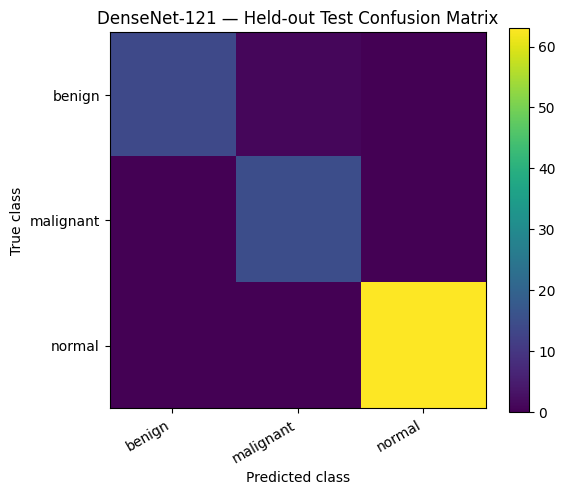


DenseNet-121 classification report
              precision    recall  f1-score   support

      benign     1.0000    0.9333    0.9655        15
   malignant     0.9375    1.0000    0.9677        15
      normal     1.0000    1.0000    1.0000        63

    accuracy                         0.9892        93
   macro avg     0.9792    0.9778    0.9778        93
weighted avg     0.9899    0.9892    0.9892        93



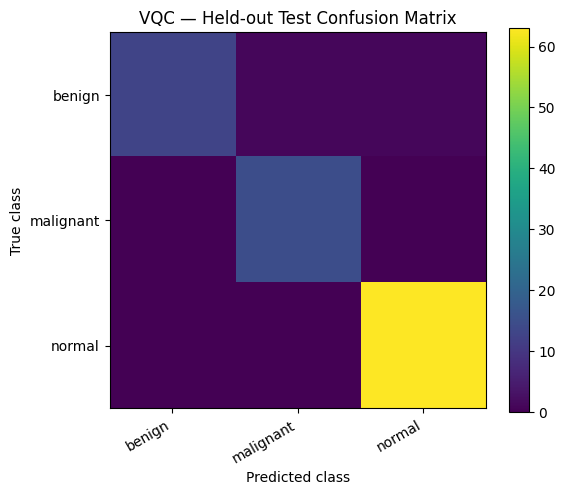


VQC classification report
              precision    recall  f1-score   support

      benign     1.0000    0.8667    0.9286        15
   malignant     0.9375    1.0000    0.9677        15
      normal     0.9844    1.0000    0.9921        63

    accuracy                         0.9785        93
   macro avg     0.9740    0.9556    0.9628        93
weighted avg     0.9793    0.9785    0.9779        93



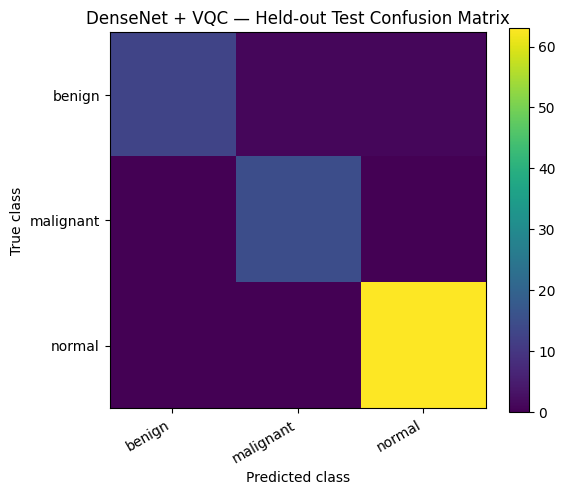


DenseNet + VQC classification report
              precision    recall  f1-score   support

      benign     1.0000    0.8667    0.9286        15
   malignant     0.9375    1.0000    0.9677        15
      normal     0.9844    1.0000    0.9921        63

    accuracy                         0.9785        93
   macro avg     0.9740    0.9556    0.9628        93
weighted avg     0.9793    0.9785    0.9779        93


OVERALL HELD-OUT TEST COMPARISON
         Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Weighted F1
  DenseNet-121    0.9892           0.9792        0.9778    0.9778       0.9892
           VQC    0.9785           0.9740        0.9556    0.9628       0.9779
DenseNet + VQC    0.9785           0.9740        0.9556    0.9628       0.9779

CLASS-WISE F1
Model      DenseNet + VQC  DenseNet-121     VQC
Class                                          
benign             0.9286        0.9655  0.9286
malignant          0.9677        0.9677  0.9677
normal             0.992

In [ ]:
model_probabilities = {
    'DenseNet-121': test_dense_probs,
    'VQC': vqc_test_probs,
    'DenseNet + VQC': combined_test_probs,
}
summary_rows = []
classwise_rows = []

for name, probs in model_probabilities.items():
    pred = probs.argmax(axis=1)
    summary_rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Macro Precision': precision_score(y_test, pred, average='macro', zero_division=0),
        'Macro Recall': recall_score(y_test, pred, average='macro', zero_division=0),
        'Macro F1': f1_score(y_test, pred, average='macro', zero_division=0),
        'Weighted F1': f1_score(y_test, pred, average='weighted', zero_division=0),
    })
    report = classification_report(y_test, pred, labels=list(range(NUM_CLASSES)),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    for class_name in CLASS_NAMES:
        classwise_rows.append({
            'Model': name, 'Class': class_name,
            'Precision': report[class_name]['precision'],
            'Recall': report[class_name]['recall'],
            'F1-score': report[class_name]['f1-score'],
            'Support': int(report[class_name]['support']),
        })
    cm = confusion_matrix(y_test, pred, labels=list(range(NUM_CLASSES)))
    safe = name.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RESULTS_DIR / f'{safe}_confusion_matrix.csv')
    pd.DataFrame({
        'source_id': test_df['source_id'].tolist(),
        'true_class': [CLASS_NAMES[int(v)] for v in y_test],
        'predicted_class': [CLASS_NAMES[int(v)] for v in pred],
        'confidence': probs.max(axis=1),
    }).to_csv(RESULTS_DIR / f'{safe}_test_predictions.csv', index=False)
    plt.figure(figsize=(6, 5))
    plt.imshow(cm, interpolation='nearest')
    plt.title(f'{name} — Held-out Test Confusion Matrix')
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30, ha='right')
    plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    plt.xlabel('Predicted class')
    plt.ylabel('True class')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f'{safe}_confusion_matrix.png', dpi=180)
    plt.show()
    plt.close()
    print(f'\n{name} classification report')
    print(classification_report(y_test, pred, labels=list(range(NUM_CLASSES)), target_names=CLASS_NAMES,
                                digits=4, zero_division=0))

summary_df = pd.DataFrame(summary_rows)
classwise_df = pd.DataFrame(classwise_rows)
summary_df.to_csv(RESULTS_DIR / 'final_test_model_comparison.csv', index=False)
classwise_df.to_csv(RESULTS_DIR / 'final_test_classwise_comparison.csv', index=False)
print('\nOVERALL HELD-OUT TEST COMPARISON')
print(summary_df.round(4).to_string(index=False))
print('\nCLASS-WISE F1')
print(classwise_df.pivot(index='Class', columns='Model', values='F1-score').round(4).to_string())
print('\nSaved test metrics and predictions to:', RESULTS_DIR)

## 11. Neuro-symbolic-style uncertainty flags

Because the new task has no ordered DR grades, the old adjacent-grade rules have been removed. This section applies transparent, configurable confidence/entropy flags to the **combined DenseNet + VQC probabilities**. These are illustrative uncertainty indicators, not validated clinical rules or a diagnostic recommendation system.

In [ ]:
NS_MIN_CONFIDENCE = 0.60
NS_MAX_NORMALIZED_ENTROPY = 0.75

def uncertainty_flags(prob_row):
    p = np.asarray(prob_row, dtype=np.float64)
    p = np.clip(p, 1e-12, 1.0)
    p = p / p.sum()
    pred = int(np.argmax(p))
    confidence = float(p[pred])
    entropy = float(-(p * np.log(p)).sum())
    normalized_entropy = entropy / math.log(NUM_CLASSES)
    rules = []
    if confidence < NS_MIN_CONFIDENCE:
        rules.append('LOW_CONFIDENCE')
    if normalized_entropy > NS_MAX_NORMALIZED_ENTROPY:
        rules.append('HIGH_UNCERTAINTY')
    if not rules:
        rules.append('NO_CONFIGURED_UNCERTAINTY_FLAG')
    return {
        'predicted_class_id': pred,
        'predicted_class': CLASS_NAMES[pred],
        'confidence': confidence,
        'normalized_entropy': normalized_entropy,
        'flags': ' | '.join(rules),
        'manual_review_flag': any(x in rules for x in ['LOW_CONFIDENCE', 'HIGH_UNCERTAINTY']),
    }

ns_rows = []
for i, probs in enumerate(combined_test_probs):
    row = uncertainty_flags(probs)
    row.update({
        'source_id': test_df.iloc[i]['source_id'],
        'true_class': CLASS_NAMES[int(y_test[i])],
        'correct_prediction': row['predicted_class_id'] == int(y_test[i]),
    })
    ns_rows.append(row)
ns_df = pd.DataFrame(ns_rows)
ns_path = RESULTS_DIR / 'combined_model_uncertainty_flags.csv'
ns_df.to_csv(ns_path, index=False)
print(ns_df['manual_review_flag'].value_counts().rename(index={True: 'Flagged for review', False: 'No configured flag'}))
print('Saved:', ns_path)
display(ns_df.head(10))

manual_review_flag
No configured flag    87
Flagged for review     6
Name: count, dtype: int64
Saved: /content/drive/MyDrive/YNet_Capsule_Results/combined_model_uncertainty_flags.csv


,predicted_class_id,predicted_class,confidence,normalized_entropy,flags,manual_review_flag,source_id,true_class,correct_prediction
0,0,benign,0.919535,0.305032,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000004,benign,True
1,0,benign,0.631740,0.699571,NO_CONFIGURED_UNCERTAINTY_FLAG,False,000075_1,benign,True
2,0,benign,0.803931,0.521955,NO_CONFIGURED_UNCERTAINTY_FLAG,False,2779,benign,True
3,0,benign,0.936777,0.248416,NO_CONFIGURED_UNCERTAINTY_FLAG,False,345-118,benign,True
4,0,benign,0.827073,0.467393,NO_CONFIGURED_UNCERTAINTY_FLAG,False,396-58,benign,True
5,0,benign,0.823836,0.492598,NO_CONFIGURED_UNCERTAINTY_FLAG,False,419-006,benign,True
6,0,benign,0.923269,0.290733,NO_CONFIGURED_UNCERTAINTY_FLAG,False,419-97,benign,True
7,2,normal,0.519020,0.931423,LOW_CONFIDENCE | HIGH_UNCERTAINTY,True,444-112,benign,False
8,0,benign,0.923797,0.276772,NO_CONFIGURED_UNCERTAINTY_FLAG,False,444-26,benign,True
9,0,benign,0.917465,0.309782,NO_CONFIGURED_UNCERTAINTY_FLAG,False,6104,benign,True


## 12. Grad-CAM++ for DenseNet-121

Grad-CAM++ produces a post-hoc localization heatmap for the selected DenseNet class. The heatmap does not establish why a model is correct, is not a segmentation mask, and is not medical evidence by itself.

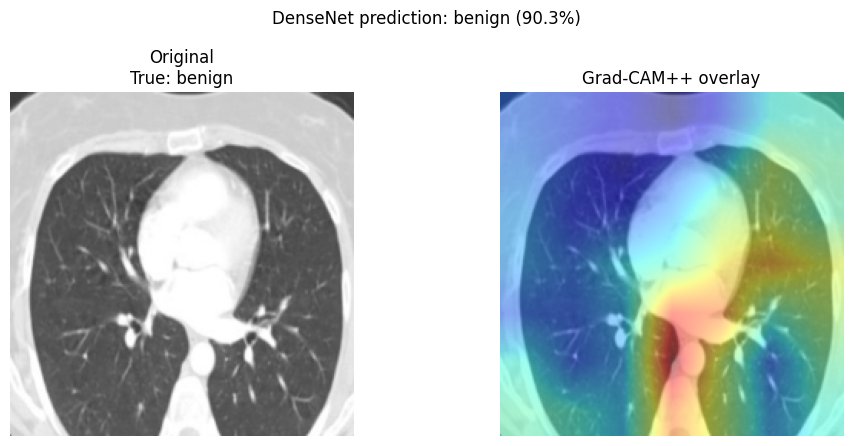

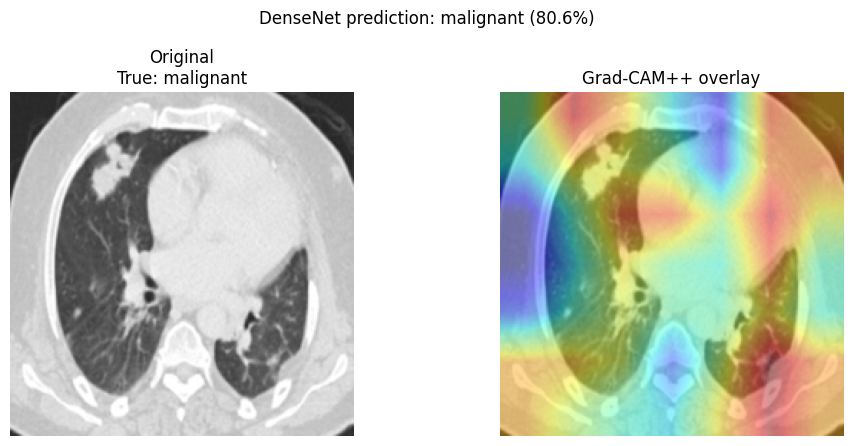

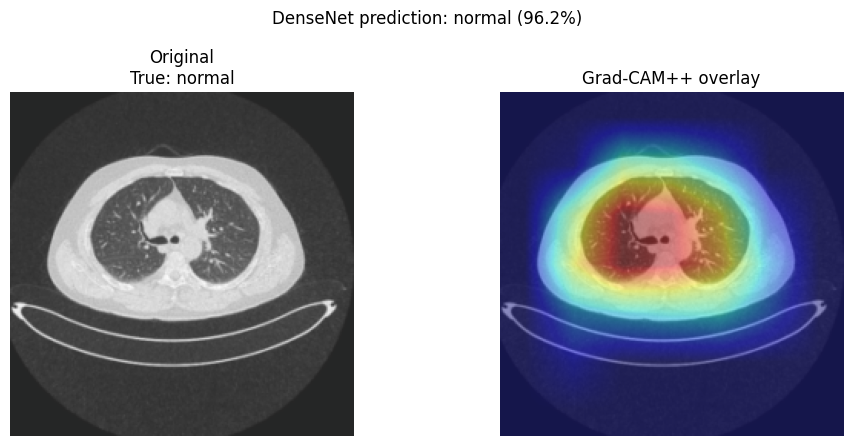

Saved Grad-CAM++ examples to: /content/drive/MyDrive/YNet_Capsule_Results


In [ ]:
cam_model = model.eval()
target_layer = cam_model.features.denseblock4
cam_store = {}

def _cam_forward_hook(module, inputs, output):
    cam_store['activations'] = output
    output.register_hook(lambda grad: cam_store.__setitem__('gradients', grad))

hook_handle = target_layer.register_forward_hook(_cam_forward_hook)

def make_gradcam_pp(input_tensor, class_idx):
    cam_model.zero_grad(set_to_none=True)
    cam_store.clear()
    logits = cam_model(input_tensor.to(DEVICE))
    logits[0, int(class_idx)].backward()
    activations = cam_store['activations'][0]
    gradients = cam_store['gradients'][0]
    grad2, grad3 = gradients.pow(2), gradients.pow(3)
    denominator = 2.0 * grad2 + (activations * grad3).sum(dim=(1, 2), keepdim=True)
    alpha = grad2 / (denominator + 1e-8)
    weights = (alpha * torch.relu(gradients)).sum(dim=(1, 2), keepdim=True)
    cam = torch.relu((weights * activations).sum(dim=0))
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    cam = torch.nn.functional.interpolate(
        cam[None, None], size=(IMAGE_SIZE, IMAGE_SIZE), mode='bilinear', align_corners=False
    )[0, 0]
    return cam.detach().cpu().numpy(), logits.detach()

def denormalize_image(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    img = tensor.cpu() * std + mean
    return np.clip(img.permute(1, 2, 0).numpy(), 0, 1)

def save_gradcam_example(dataset_index, true_label):
    x, _, _ = test_ds[dataset_index]
    input_tensor = x.unsqueeze(0).to(DEVICE)
    cam_model.eval()
    with torch.enable_grad():
        initial_logits = cam_model(input_tensor)
        predicted_class = int(initial_logits.argmax(dim=1).item())
        heatmap, logits = make_gradcam_pp(input_tensor, predicted_class)
    probs = torch.softmax(logits, dim=1)[0]
    pred = int(probs.argmax().item())
    confidence = float(probs[pred].item())
    original = denormalize_image(x)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
    axes[0].imshow(original)
    axes[0].set_title(f'Original\nTrue: {CLASS_NAMES[true_label]}')
    axes[1].imshow(original)
    axes[1].imshow(heatmap, cmap='jet', alpha=0.42, vmin=0, vmax=1)
    axes[1].set_title('Grad-CAM++ overlay')
    for ax in axes:
        ax.axis('off')
    fig.suptitle(f'DenseNet prediction: {CLASS_NAMES[pred]} ({confidence:.1%})')
    fig.tight_layout()
    safe = CLASS_NAMES[true_label].replace(' ', '_')
    out_path = RESULTS_DIR / f'gradcampp_true_{safe}_testidx_{dataset_index}.png'
    fig.savefig(out_path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return {
        'test_index': dataset_index,
        'source_id': test_df.iloc[dataset_index]['source_id'],
        'true_class': CLASS_NAMES[true_label],
        'predicted_class': CLASS_NAMES[pred],
        'confidence': confidence,
        'file': str(out_path),
    }

cam_rows = []
for class_id in range(NUM_CLASSES):
    indices = np.flatnonzero(y_test == class_id)
    if len(indices):
        cam_rows.append(save_gradcam_example(int(indices[0]), class_id))

hook_handle.remove()
pd.DataFrame(cam_rows).to_csv(RESULTS_DIR / 'gradcam_plus_plus_examples.csv', index=False)
print('Saved Grad-CAM++ examples to:', RESULTS_DIR)

## 13. Final run summary and saved artifacts

Key outputs in `My Drive/YNet_Capsule_Results` include the split manifest, best DenseNet checkpoint and history, new VQC checkpoint/history, fitted VQC preprocessing objects, class-wise and overall test metrics, predictions, confusion matrices, uncertainty flags, and Grad-CAM++ examples.

### Interpretation limitations
- The ZIP contains 1,608 image files (Train + Val), including transformed variants. The notebook deliberately uses one canonical image per source ID and excludes IDs that appear in multiple classes; therefore the actual model sample count (roughly 600 source images) is much smaller than the file count.
- The classes are imbalanced: `normal` has roughly four times as many source images as `benign` or `malignant`. Class-weighted loss and Macro-F1 are used, but read per-class recall and the confusion matrices, not accuracy alone.
- `Normal` images are 512×512 while the other classes are mostly 256×256. A common pre-resize is applied, but resolution/source differences can still act as a shortcut; treat very high scores with caution and check the Grad-CAM++ maps.
- The test set is small (roughly 15 `benign` and 15 `malignant` source images), so metrics may be noisy. Treat this as an experimental classification pipeline, not a clinically validated system.
- This is three-class image classification only. No segmentation masks were present in the ZIP, so no Y-Net segmentation results are produced.
- DenseNet + VQC fusion is probability-level late fusion. Its performance is reported separately and must not be claimed to improve over DenseNet unless the measured held-out metrics support that claim.

In [ ]:
print('RUN COMPLETE')
print('Dataset root:', DATA_ROOT)
print('Canonical images:', len(manifest), '| train:', len(train_df), '| valid:', len(valid_df), '| test:', len(test_df))
print('DenseNet checkpoint:', DENSENET_CKPT)
print('VQC checkpoint:', VQC_CKPT)
print('Fusion weights -> DenseNet:', BEST_DENSENET_WEIGHT, '| VQC:', BEST_VQC_WEIGHT)
print('Results directory:', RESULTS_DIR)
print('Metric table:')
display(summary_df)

RUN COMPLETE
Dataset root: /content/ynet_capsule_extracted/Y-Net_Capsule
Canonical images: 615 | train: 430 | valid: 92 | test: 93
DenseNet checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/densenet121_capsule3class_best.pt
VQC checkpoint: /content/drive/MyDrive/YNet_Capsule_Results/vqc_capsule3class_best.pt
Fusion weights -> DenseNet: 0.1 | VQC: 0.9
Results directory: /content/drive/MyDrive/YNet_Capsule_Results
Metric table:


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
0,DenseNet-121,0.989247,0.979167,0.977778,0.977753,0.989235
1,VQC,0.978495,0.973958,0.955556,0.962813,0.977942
2,DenseNet + VQC,0.978495,0.973958,0.955556,0.962813,0.977942
